# Machine Learning Foundations — Lecture Notebook

This notebook is the code companion to the **Learning Lab** (interactive page) and the **Teaching Handbook** (printable notes). Each part matches one lesson:

| Part | Lesson | Learning Lab tab |
|---|---|---|
| 1 | Gradient descent | 1 Gradient descent |
| 2 | Regression | 2 Regression |
| 3 | Classification | 3 Classification |
| 4 | Loss functions | 4 Loss functions |
| 5 | Overfitting and underfitting | 5 Overfitting |
| 6 | Optimizers | 6 Optimizers |

**How to use it in class.** Run the cells from top to bottom (Shift + Enter). Every model is written from scratch with NumPy, so students can see every formula as code. Each part ends with exercises; solutions are in the appendix at the end.

**Requirements:** Python 3, NumPy and Matplotlib. Nothing else.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True)

# Colours used for the optimizers in Part 6 (the same as in the Learning Lab)
COLORS = {"GD": "#4a5567", "Momentum": "#d97706", "Nesterov": "#7c3aed",
          "AdaGrad": "#15803d", "RMSProp": "#0e7490", "Adam": "#dc2626"}
BLUE, ORANGE, RED = "#1f6fd0", "#e0600f", "#d1352b"
print("NumPy", np.__version__, "is ready.")

NumPy 2.5.4 is ready.


---
# Part 1. Gradient descent

**Big idea.** A model has parameters (numbers it can change). The **loss** $L(\theta)$ says how wrong the model is. Training means finding the parameters with the lowest loss. Gradient descent does this step by step:

$$\theta_{\text{new}} = \theta - \eta\,\nabla L(\theta)$$

* $\nabla L$ is the **gradient** (with one parameter: the derivative, the slope). It points **uphill**.
* $\eta$ is the **learning rate**: the step size.
* We subtract the gradient, so we always move **downhill**.

## 1.1 The slope tells us which way is uphill

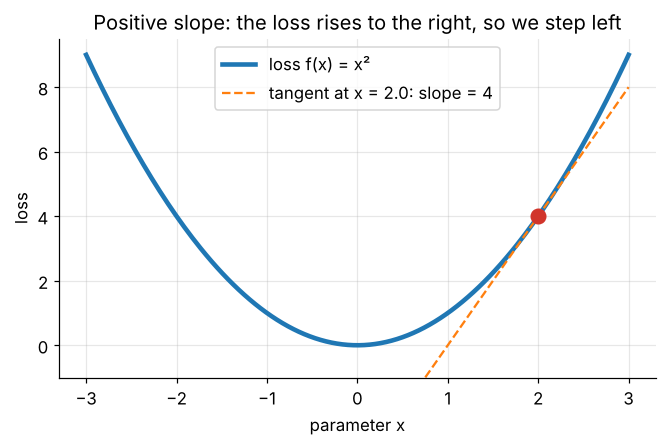

In [2]:
def f(x):
    return x ** 2          # the loss

def df(x):
    return 2 * x           # its derivative (the slope)

xs = np.linspace(-3, 3, 200)
x0 = 2.0
plt.plot(xs, f(xs), lw=3, label="loss f(x) = x²")
plt.plot(xs, f(x0) + df(x0) * (xs - x0), "--", label=f"tangent at x = {x0}: slope = {df(x0):.0f}")
plt.scatter([x0], [f(x0)], s=90, zorder=3, color=RED)
plt.ylim(-1, 9.5); plt.xlabel("parameter x"); plt.ylabel("loss")
plt.title("Positive slope: the loss rises to the right, so we step left")
plt.legend(); plt.show()

## 1.2 Gradient descent in five lines

The function below is the whole algorithm. Compare the printed table with the worked example in the handbook (Lesson 1).

In [3]:
def gradient_descent_1d(grad, x0, lr, steps):
    """Run gradient descent on one parameter. Returns every position visited."""
    x = x0
    path = [x]
    for _ in range(steps):
        x = x - lr * grad(x)                      # the update rule
        path.append(x)
        if not np.isfinite(x) or abs(x) > 1e6:    # stop if it blew up
            break
    return np.array(path)

path = gradient_descent_1d(df, x0=2.5, lr=0.1, steps=4)
print(" step       x      f(x)    f'(x)")
for t, x in enumerate(path):
    print(f"{t:5d} {x:8.3f} {f(x):8.3f} {df(x):8.3f}")

 step       x      f(x)    f'(x)
    0    2.500    6.250    5.000
    1    2.000    4.000    4.000
    2    1.600    2.560    3.200
    3    1.280    1.638    2.560
    4    1.024    1.049    2.048


Notice that the steps shrink (0.50, 0.40, 0.32, …) although $\eta$ is fixed: near the bottom the slope is smaller, and the step is $\eta \times$ slope.

## 1.3 The learning rate decides everything

For $f(x)=x^2$ the update is $x_{\text{new}} = (1-2\eta)\,x$. It converges only if $|1-2\eta|<1$, that is $0<\eta<1$.

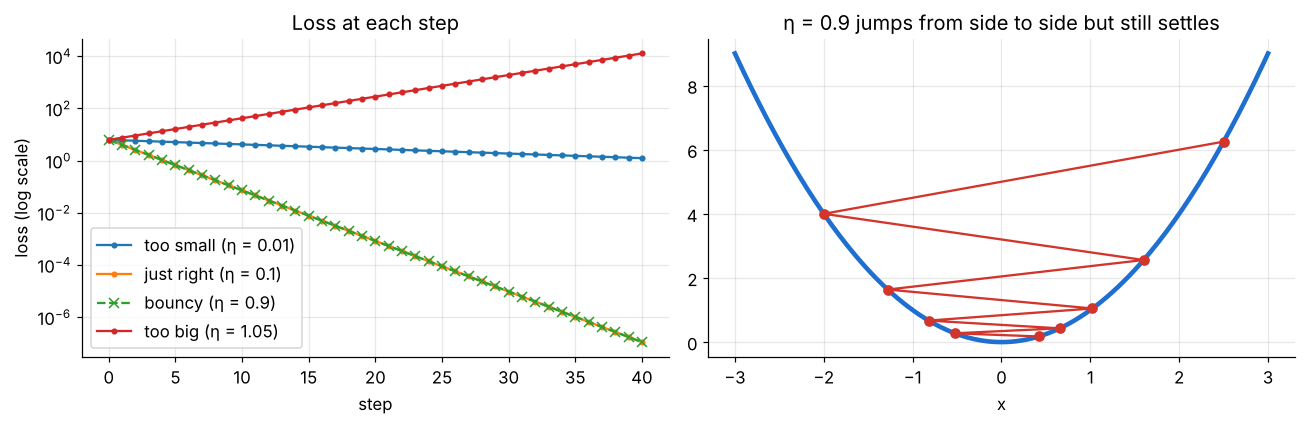

In [4]:
rates = {"too small (η = 0.01)": 0.01, "just right (η = 0.1)": 0.1,
         "bouncy (η = 0.9)": 0.9, "too big (η = 1.05)": 1.05}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, lr in rates.items():
    p = gradient_descent_1d(df, 2.5, lr, 40)
    style = dict(ls="--", marker="x", ms=6) if lr == 0.9 else dict(marker="o", ms=3)
    axes[0].plot(f(p), label=name, **style)
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("Loss at each step"); axes[0].legend()

p = gradient_descent_1d(df, 2.5, 0.9, 8)
axes[1].plot(xs, f(xs), lw=3, color=BLUE)
axes[1].plot(p, f(p), "o-", color=RED)
axes[1].set_title("η = 0.9 jumps from side to side but still settles"); axes[1].set_xlabel("x")
plt.tight_layout(); plt.show()

Look closely: the loss curves for $\eta = 0.1$ and $\eta = 0.9$ lie exactly on top of each other. Both have $|1-2\eta| = 0.8$, so the loss shrinks by the same factor each step. The *paths* are different, though: $\eta = 0.1$ creeps in from one side, $\eta = 0.9$ jumps across the valley every step (right panel). A good question for the class: why?

## 1.4 Local and global minima

$g(x) = x^4 - 3x^2 + x$ has two valleys. Gradient descent stops in whichever valley it reaches first, so the **starting point** and the **learning rate** both matter.

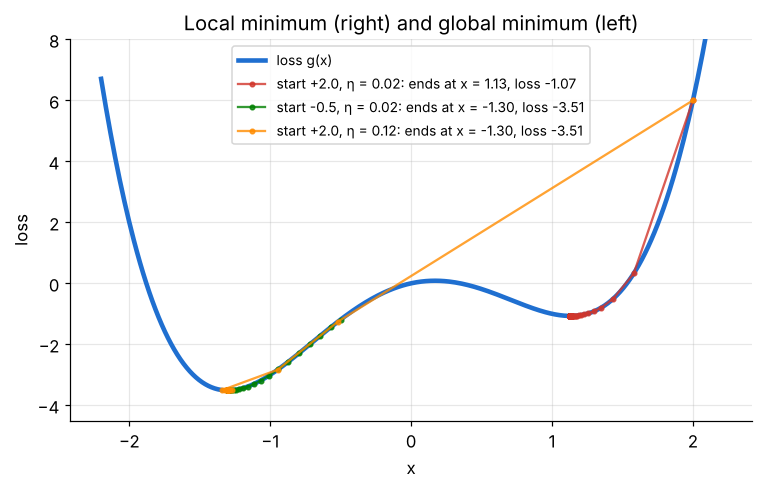

In [5]:
g  = lambda x: x**4 - 3*x**2 + x
dg = lambda x: 4*x**3 - 6*x + 1

xs2 = np.linspace(-2.2, 2.2, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(xs2, g(xs2), lw=3, color=BLUE, label="loss g(x)")
runs = [(2.0, 0.02, RED), (-0.5, 0.02, "green"), (2.0, 0.12, "darkorange")]
for x0, lr, c in runs:
    p = gradient_descent_1d(dg, x0, lr, 300)
    plt.plot(p, g(p), "o-", ms=3, color=c, alpha=0.8,
             label=f"start {x0:+.1f}, η = {lr}: ends at x = {p[-1]:.2f}, loss {g(p[-1]):.2f}")
plt.ylim(-4.5, 8); plt.xlabel("x"); plt.ylabel("loss"); plt.legend(fontsize=9)
plt.title("Local minimum (right) and global minimum (left)"); plt.show()

### Exercises — Part 1
1. Run gradient descent on $f(x) = (x-3)^2$ from $x_0 = 0$ with $\eta = 0.1$ for 50 steps. Where does it end? Why?
2. For $f(x) = 4x^2$, find the largest learning rate that still converges. Check your answer with code.
3. On $g(x)$ above, start at $x_0 = 2$ and try learning rates 0.02, 0.06, 0.12, 0.2. Which ones reach the global minimum?

---
# Part 2. Regression

**Big idea.** Regression predicts a number. A linear model is $\hat y = w_0 + w_1 x$. We measure how wrong it is with the **mean squared error** and minimise it with gradient descent.

$$\text{MSE} = \frac1n\sum_{i=1}^n(\hat y_i - y_i)^2
\qquad
\frac{\partial\,\text{MSE}}{\partial w_0} = \frac2n\sum(\hat y_i-y_i)
\qquad
\frac{\partial\,\text{MSE}}{\partial w_1} = \frac2n\sum(\hat y_i-y_i)\,x_i$$

## 2.1 Data

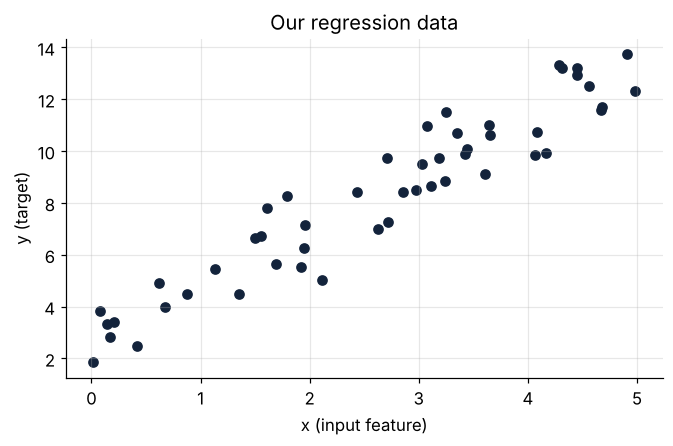

In [6]:
rng = np.random.default_rng(0)
n = 50
x = rng.uniform(0, 5, n)
y = 3 + 2 * x + rng.normal(0, 1, n)        # true line: y = 3 + 2x, plus noise

plt.scatter(x, y, color="#13233b")
plt.xlabel("x (input feature)"); plt.ylabel("y (target)"); plt.title("Our regression data"); plt.show()

## 2.2 Model, loss and gradients as code

In [7]:
def predict(x, w0, w1):
    return w0 + w1 * x

def mse(y_hat, y):
    return np.mean((y_hat - y) ** 2)

def mse_gradients(x, y, w0, w1):
    err = predict(x, w0, w1) - y            # one error per example
    return 2 * np.mean(err), 2 * np.mean(err * x)

# Check the worked example from the handbook: data (1,2), (2,4), (3,5), one step with η = 0.1
xe, ye = np.array([1., 2., 3.]), np.array([2., 4., 5.])
w0, w1 = 0.0, 0.0
print("MSE before:", mse(predict(xe, w0, w1), ye))
g0, g1 = mse_gradients(xe, ye, w0, w1)
print(f"gradients: dw0 = {g0:.3f}, dw1 = {g1:.3f}")
w0, w1 = w0 - 0.1 * g0, w1 - 0.1 * g1
print(f"after one step: w0 = {w0:.3f}, w1 = {w1:.3f}, MSE = {mse(predict(xe, w0, w1), ye):.3f}")

MSE before: 15.0
gradients: dw0 = -7.333, dw1 = -16.667
after one step: w0 = 0.733, w1 = 1.667, MSE = 0.234


## 2.3 Training with gradient descent

learned model: ŷ = 2.757 + 2.105·x    final MSE = 0.993


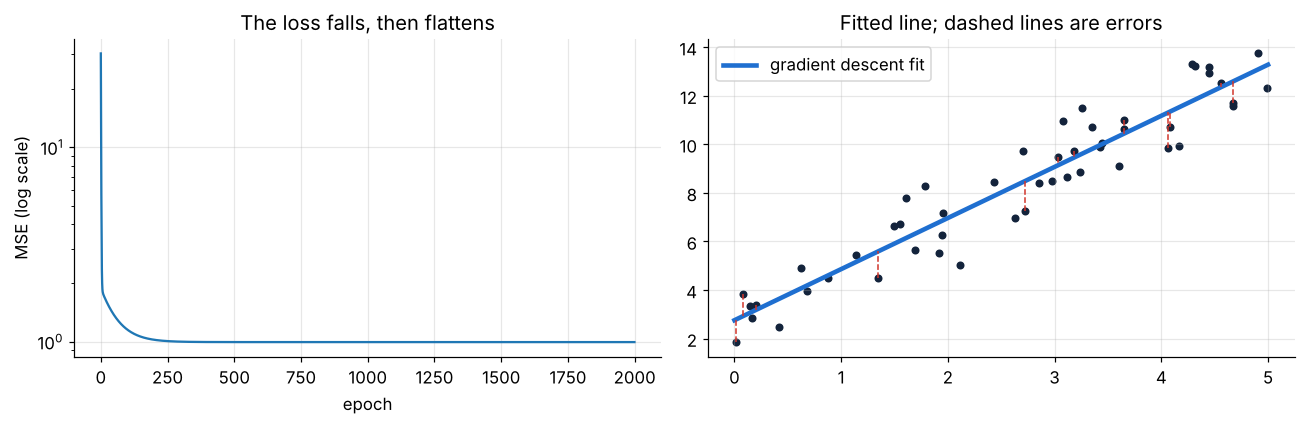

In [8]:
w0, w1, lr = 0.0, 0.0, 0.02
history = []
for epoch in range(2000):
    g0, g1 = mse_gradients(x, y, w0, w1)
    w0 -= lr * g0
    w1 -= lr * g1
    history.append(mse(predict(x, w0, w1), y))

print(f"learned model: ŷ = {w0:.3f} + {w1:.3f}·x    final MSE = {history[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history); axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE (log scale)"); axes[0].set_title("The loss falls, then flattens")
axes[1].scatter(x, y, color="#13233b", s=18)
xx = np.linspace(0, 5, 100)
axes[1].plot(xx, predict(xx, w0, w1), color=BLUE, lw=3, label="gradient descent fit")
for xi, yi in zip(x[:12], y[:12]):                        # show some errors
    axes[1].plot([xi, xi], [yi, predict(xi, w0, w1)], "--", color=RED, lw=1)
axes[1].set_title("Fitted line; dashed lines are errors"); axes[1].legend()
plt.tight_layout(); plt.show()

## 2.4 The exact answer: the normal equation

Stack a column of ones and the feature into a matrix $X$. The best weights are $w^* = (X^\top X)^{-1}X^\top y$. Gradient descent should agree.

In [9]:
X = np.column_stack([np.ones_like(x), x])
w_exact = np.linalg.solve(X.T @ X, X.T @ y)        # solves (XᵀX) w = Xᵀy
print("normal equation :", w_exact)
print("gradient descent:", np.array([w0, w1]))

normal equation : [2.7575 2.1047]
gradient descent: [2.7575 2.1047]


## 2.5 Curves: polynomial regression

Add powers of $x$ as extra features: $\hat y = w_0 + w_1x + w_2x^2 + \dots + w_dx^d$. It is still *linear* regression, because the model is linear in the weights.

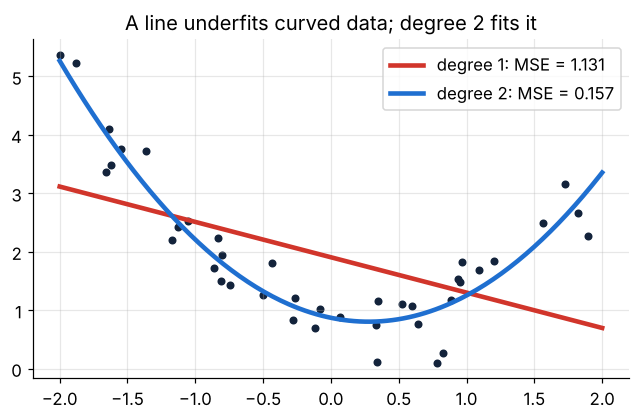

In [10]:
def poly_features(x, degree):
    """Columns 1, x, x², …, x^degree."""
    return np.column_stack([x ** k for k in range(degree + 1)])

def fit_poly(x, y, degree, lam=0.0):
    """Least squares (optionally ridge-regularised, bias not penalised)."""
    X = poly_features(x, degree)
    if lam > 0:
        P = np.sqrt(lam * len(x)) * np.eye(degree + 1)[1:]
        X, y = np.vstack([X, P]), np.concatenate([y, np.zeros(degree)])
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    return w

def predict_poly(w, x):
    return poly_features(x, len(w) - 1) @ w

rng = np.random.default_rng(3)
xq = rng.uniform(-2, 2, 40)
yq = 1 - 0.5 * xq + 0.8 * xq**2 + rng.normal(0, 0.4, 40)

xx = np.linspace(-2, 2, 200)
plt.scatter(xq, yq, color="#13233b", s=18)
for d, c in [(1, RED), (2, BLUE)]:
    w = fit_poly(xq, yq, d)
    plt.plot(xx, predict_poly(w, xx), lw=3, color=c,
             label=f"degree {d}: MSE = {mse(predict_poly(w, xq), yq):.3f}")
plt.legend(); plt.title("A line underfits curved data; degree 2 fits it"); plt.show()

## 2.6 Measuring a regression model

| Metric | Formula | Meaning |
|---|---|---|
| MSE | $\frac1n\sum(\hat y-y)^2$ | Average squared error |
| RMSE | $\sqrt{\text{MSE}}$ | Typical error, in the units of $y$ |
| MAE | $\frac1n\sum|\hat y-y|$ | Average absolute error |
| $R^2$ | $1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$ | Share of variation explained (1 = perfect) |

In [11]:
def regression_report(y, y_hat):
    mse_ = np.mean((y_hat - y) ** 2)
    return {"MSE": mse_, "RMSE": np.sqrt(mse_), "MAE": np.mean(np.abs(y_hat - y)),
            "R²": 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)}

for name, value in regression_report(y, predict(x, *w_exact)).items():
    print(f"{name:5s} = {value:.3f}")

MSE   = 0.993
RMSE  = 0.997
MAE   = 0.843
R²    = 0.904


### Exercises — Part 2
1. Generate data from $y = 1 - 3x + \text{noise}$ and fit it with the gradient descent loop above. Do you recover $w_0 \approx 1$, $w_1 \approx -3$?
2. Set the learning rate to 0.2 in Section 2.3. What happens to the loss, and why?
3. Fit degree 1, 2 and 6 polynomials to `xq, yq` and compare their MSE. Is the lowest training MSE the best model? (Part 5 answers this properly.)

---
# Part 3. Classification with logistic regression

**Big idea.** Labels are $y\in\{0,1\}$. The model computes a score $z = w^\top x + b$ and turns it into a probability with the **sigmoid**:

$$p = \sigma(z) = \frac{1}{1+e^{-z}}$$

It predicts class 1 when $p \ge 0.5$, which is when $z\ge 0$: the **decision boundary** is $w^\top x + b = 0$. It is trained by minimising **binary cross-entropy**:

$$L = -\frac1n\sum_{i}\big[y_i\ln p_i + (1-y_i)\ln(1-p_i)\big], \qquad \frac{\partial L}{\partial w} = \frac1n\sum_i (p_i-y_i)\,x_i$$

## 3.1 The sigmoid

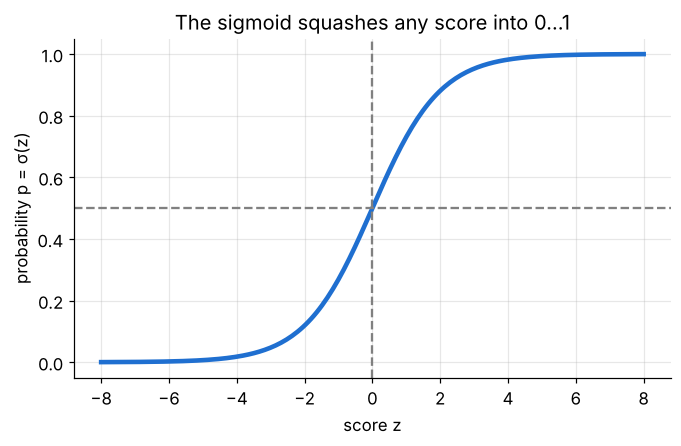

{-4: 0.018, -2: 0.119, 0: 0.5, 2: 0.881, 4: 0.982}

In [12]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z), lw=3, color=BLUE)
plt.axhline(0.5, ls="--", color="gray"); plt.axvline(0, ls="--", color="gray")
plt.xlabel("score z"); plt.ylabel("probability p = σ(z)")
plt.title("The sigmoid squashes any score into 0…1"); plt.show()
print({zz: round(float(sigmoid(zz)), 3) for zz in [-4, -2, 0, 2, 4]})

## 3.2 Training logistic regression from scratch

In [13]:
def bce(p, y, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)                   # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def train_logistic(F, y, lr=0.5, epochs=2000, lam=0.0):
    """F: features (n × d), no bias column. Returns weights, bias, loss history."""
    n, d = F.shape
    w, b, history = np.zeros(d), 0.0, []
    for _ in range(epochs):
        p = sigmoid(F @ w + b)
        err = p - y                                 # (prediction − truth)
        w -= lr * (F.T @ err / n + 2 * lam * w)
        b -= lr * err.mean()
        history.append(bce(p, y))
    return w, b, np.array(history)

rng = np.random.default_rng(1)
XA = rng.normal([-1.0, -1.0], 0.7, (60, 2))       # class A (y = 0)
XB = rng.normal([1.2, 1.0], 0.7, (60, 2))         # class B (y = 1)
X2 = np.vstack([XA, XB]); y2 = np.r_[np.zeros(60), np.ones(60)]

w, b, hist = train_logistic(X2, y2, lr=0.5, epochs=1500)
acc = np.mean((sigmoid(X2 @ w + b) >= 0.5) == y2)
print(f"weights = {w}, bias = {b:.3f}, final loss = {hist[-1]:.3f}, accuracy = {acc:.0%}")

weights = [4.8792 4.6797], bias = -0.057, final loss = 0.004, accuracy = 100%


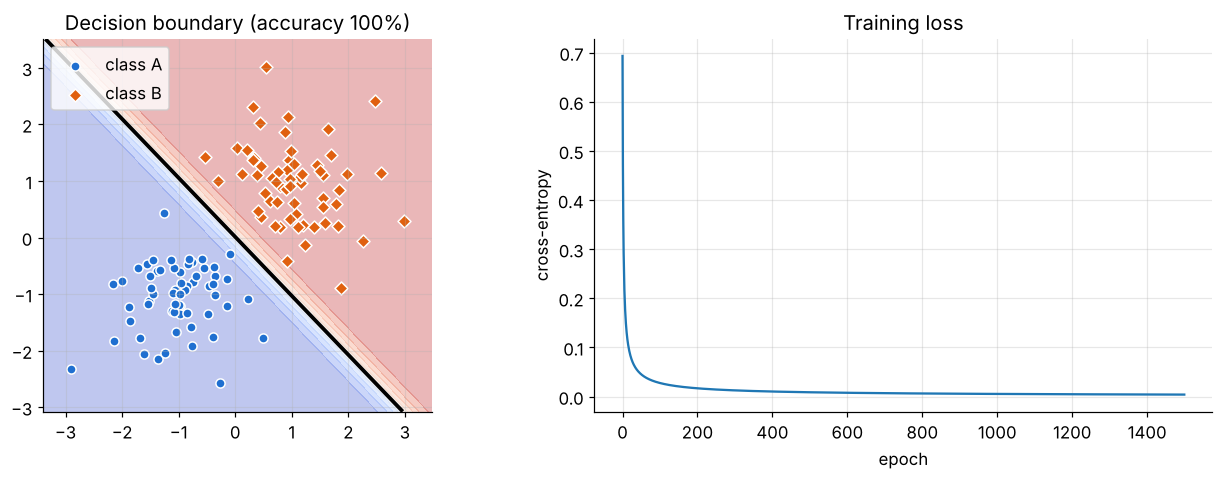

In [14]:
def plot_boundary(ax, feature_fn, w, b, X, y, title):
    """Shade the predicted probability and draw the p = 0.5 boundary."""
    pad = 0.5
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 250),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 250))
    grid = np.c_[gx.ravel(), gy.ravel()]
    p = sigmoid(feature_fn(grid) @ w + b).reshape(gx.shape)
    ax.contourf(gx, gy, p, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.35)
    ax.contour(gx, gy, p, levels=[0.5], colors="black", linewidths=2.5)
    ax.scatter(*X[y == 0].T, color=BLUE, edgecolor="white", label="class A")
    ax.scatter(*X[y == 1].T, color=ORANGE, marker="D", edgecolor="white", label="class B")
    ax.set_title(title); ax.legend(loc="upper left"); ax.set_aspect("equal")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_boundary(axes[0], lambda X: X, w, b, X2, y2, f"Decision boundary (accuracy {acc:.0%})")
axes[1].plot(hist); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("cross-entropy")
axes[1].set_title("Training loss")
plt.tight_layout(); plt.show()

## 3.3 Check the handbook's worked example

One example $x=(1,2)$, $y=1$, start $w=(0.5,-0.5)$, $b=0$, $\eta=1$.

In [15]:
xw, yw = np.array([1.0, 2.0]), 1.0
w_ex, b_ex = np.array([0.5, -0.5]), 0.0
z0 = xw @ w_ex + b_ex; p0 = sigmoid(z0)
print(f"before: z = {z0:.3f}, p = {p0:.3f}, loss = {-np.log(p0):.3f}")
w_ex = w_ex - 1.0 * (p0 - yw) * xw
b_ex = b_ex - 1.0 * (p0 - yw)
z1 = xw @ w_ex + b_ex; p1 = sigmoid(z1)
print(f"after:  w = {w_ex}, b = {b_ex:.3f}, z = {z1:.3f}, p = {p1:.3f}, loss = {-np.log(p1):.3f}")

before: z = -0.500, p = 0.378, loss = 0.974
after:  w = [1.1225 0.7449], b = 0.622, z = 3.235, p = 0.962, loss = 0.039


## 3.4 Curved boundaries with new features

A straight line cannot separate a ring from its centre. Adding the features $x_1^2,\ x_1x_2,\ x_2^2$ lets the same model draw a circle.

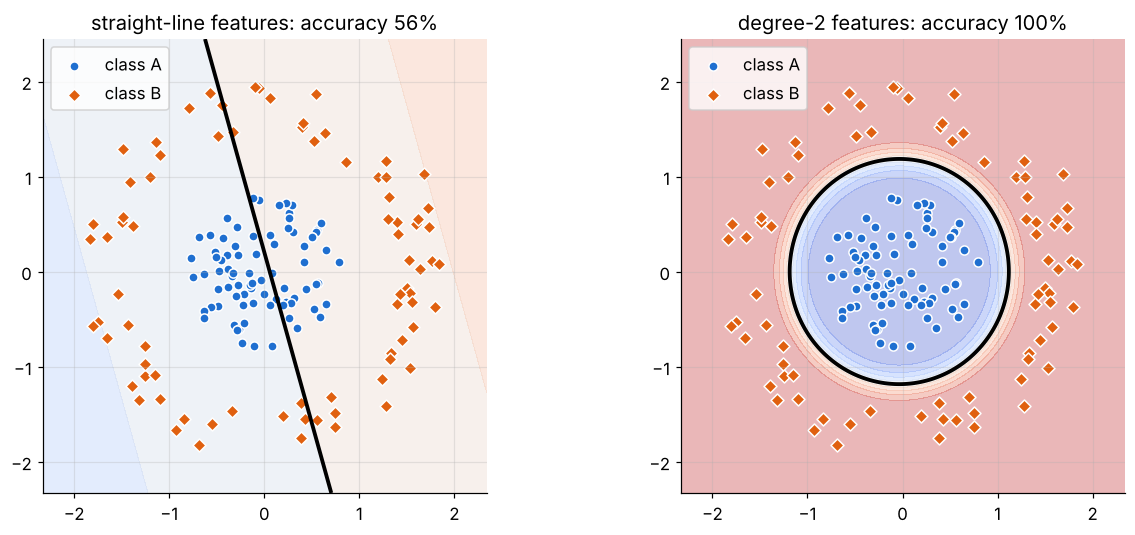

In [16]:
rng = np.random.default_rng(2)
a1, a2 = rng.uniform(0, 2*np.pi, 80), rng.uniform(0, 2*np.pi, 80)
r1, r2 = 0.8 * np.sqrt(rng.uniform(0, 1, 80)), rng.uniform(1.4, 2.0, 80)
Xc = np.vstack([np.c_[r1*np.cos(a1), r1*np.sin(a1)], np.c_[r2*np.cos(a2), r2*np.sin(a2)]])
yc = np.r_[np.zeros(80), np.ones(80)]

linear = lambda X: X
quadratic = lambda X: np.c_[X, X[:, 0]**2, X[:, 0]*X[:, 1], X[:, 1]**2]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, fn) in zip(axes, [("straight-line features", linear), ("degree-2 features", quadratic)]):
    wc, bc, _ = train_logistic(fn(Xc), yc, lr=0.3, epochs=3000)
    accc = np.mean((sigmoid(fn(Xc) @ wc + bc) >= 0.5) == yc)
    plot_boundary(ax, fn, wc, bc, Xc, yc, f"{name}: accuracy {accc:.0%}")
plt.tight_layout(); plt.show()

## 3.5 Beyond accuracy: confusion matrix, precision, recall, F1

| | Predicted 1 | Predicted 0 |
|---|---|---|
| **Truly 1** | TP | FN |
| **Truly 0** | FP | TN |

Precision $= \frac{TP}{TP+FP}$, recall $= \frac{TP}{TP+FN}$, $F_1 = \frac{2PR}{P+R}$.

In [17]:
def classification_report(y, y_pred):
    tp = np.sum((y == 1) & (y_pred == 1)); tn = np.sum((y == 0) & (y_pred == 0))
    fp = np.sum((y == 0) & (y_pred == 1)); fn = np.sum((y == 1) & (y_pred == 0))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, accuracy=(tp + tn) / len(y),
                precision=precision, recall=recall, F1=f1)

# Overlapping classes, so the model cannot be perfect
rng = np.random.default_rng(4)
Xov = np.vstack([rng.normal([-0.5, -0.5], 1.0, (100, 2)), rng.normal([0.7, 0.6], 1.0, (100, 2))])
yov = np.r_[np.zeros(100), np.ones(100)]
w_ov, b_ov, _ = train_logistic(Xov, yov, lr=0.5, epochs=1500)

for threshold in [0.3, 0.5, 0.8]:
    pred = (sigmoid(Xov @ w_ov + b_ov) >= threshold).astype(int)
    r = classification_report(yov, pred)
    print(f"threshold {threshold}: " + ", ".join(f"{k} = {v:.2f}" if isinstance(v, float) else f"{k} = {v}" for k, v in r.items()))

threshold 0.3: TP = 92, FP = 35, FN = 8, TN = 65, accuracy = 0.79, precision = 0.72, recall = 0.92, F1 = 0.81
threshold 0.5: TP = 80, FP = 20, FN = 20, TN = 80, accuracy = 0.80, precision = 0.80, recall = 0.80, F1 = 0.80
threshold 0.8: TP = 52, FP = 3, FN = 48, TN = 97, accuracy = 0.74, precision = 0.95, recall = 0.52, F1 = 0.67


A higher threshold makes the model more careful about saying "class 1": precision goes up, recall goes down.

### Exercises — Part 3
1. Build an XOR dataset (four clusters at $(\pm1,\pm1)$, label 1 when $x_1x_2<0$). Show that linear features fail, then add the single feature $x_1x_2$ and train again.
2. Imbalanced data: make 190 points of class 0 and 10 of class 1. What accuracy does "always predict 0" get? What are its precision and recall?
3. In `train_logistic`, replace cross-entropy's gradient with the MSE gradient $2(p-y)\,p(1-p)\,x$. Does training get slower? (Part 4 explains why.)

---
# Part 4. Loss functions

**Big idea.** The loss defines what "wrong" means. The model becomes whatever minimises it, so choosing the loss is choosing what the model cares about.

| Loss | Formula (one example) | Task | Big mistakes |
|---|---|---|---|
| MSE | $e^2$ with $e=\hat y-y$ | Regression | Squared, so they dominate (outlier-sensitive) |
| MAE | $|e|$ | Regression | Linear, robust to outliers |
| Huber | $\tfrac12e^2$ if $|e|\le\delta$, else $\delta(|e|-\tfrac12\delta)$ | Regression | Square near 0, linear far away |
| Binary cross-entropy | $-[y\ln p+(1-y)\ln(1-p)]$ | 2 classes | Huge for confident wrong answers |
| Categorical cross-entropy | $-\ln p_{\text{true}}$ (after softmax) | many classes | Same idea |
| Hinge | $\max(0,1-yz)$, $y\in\{-1,+1\}$ | 2 classes (SVM) | Zero once correct with a margin |

## 4.1 Regression losses side by side

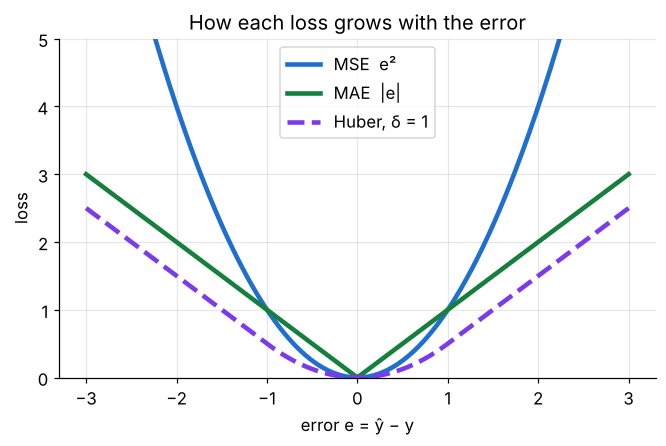

error | MSE term, pull 2e | MAE term, pull sign(e) | Huber term, pull clip(e)
 -0.5 |   0.25,  -1.0     |  0.50,   -1          | 0.125, -0.5
  1.0 |   1.00,   2.0     |  1.00,    1          | 0.500,  1.0
  4.0 |  16.00,   8.0     |  4.00,    1          | 3.500,  1.0


In [18]:
def mse_loss(e):            return e ** 2
def mae_loss(e):            return np.abs(e)
def huber_loss(e, delta=1): return np.where(np.abs(e) <= delta, 0.5 * e**2, delta * (np.abs(e) - 0.5 * delta))

e = np.linspace(-3, 3, 400)
plt.plot(e, mse_loss(e), lw=3, label="MSE  e²", color=BLUE)
plt.plot(e, mae_loss(e), lw=3, label="MAE  |e|", color="#15803d")
plt.plot(e, huber_loss(e, 1.0), lw=3, ls="--", label="Huber, δ = 1", color="#7c3aed")
plt.ylim(0, 5); plt.xlabel("error e = ŷ − y"); plt.ylabel("loss"); plt.legend()
plt.title("How each loss grows with the error"); plt.show()

errors = np.array([-0.5, 1.0, 4.0])
print("error | MSE term, pull 2e | MAE term, pull sign(e) | Huber term, pull clip(e)")
for ei in errors:
    print(f"{ei:5.1f} | {mse_loss(ei):6.2f}, {2*ei:5.1f}     | {mae_loss(ei):5.2f}, {np.sign(ei):4.0f}          | "
          f"{float(huber_loss(ei)):5.3f}, {np.clip(ei, -1, 1):4.1f}")

## 4.2 Outliers: MSE gets dragged, MAE and Huber do not

We fit the same line three times, each time minimising a different loss with gradient descent. The gradient of each loss with respect to the prediction is: MSE $2e$, MAE $\text{sign}(e)$, Huber $\text{clip}(e,-\delta,\delta)$.

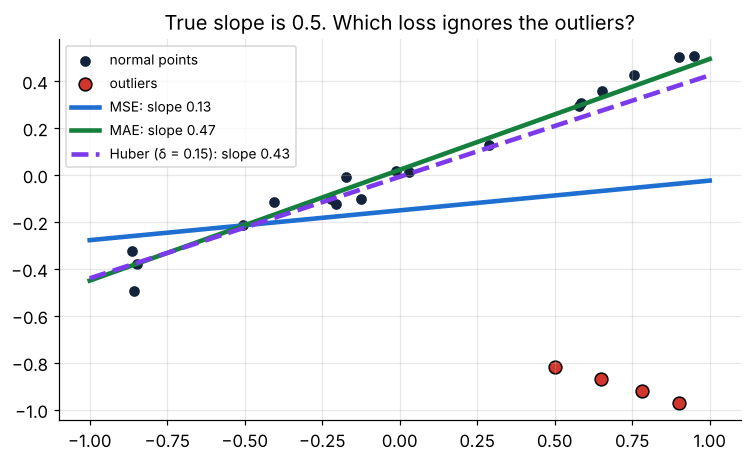

In [19]:
def fit_line(x, y, loss_grad, lr=0.1, epochs=6000):
    w0 = w1 = 0.0
    for t in range(epochs):
        g = loss_grad(w0 + w1 * x - y)               # d loss / d prediction, per example
        step = lr / (1 + t / 500)                     # slowly shrinking step (helps MAE settle)
        w0 -= step * np.mean(g)
        w1 -= step * np.mean(g * x)
    return w0, w1

rng = np.random.default_rng(5)
xo = rng.uniform(-0.95, 0.95, 18)
yo = 0.5 * xo + 0.05 + rng.normal(0, 0.07, 18)
x_out = np.array([0.5, 0.65, 0.78, 0.9]); y_out = np.array([-0.82, -0.87, -0.92, -0.97])
xo_all, yo_all = np.r_[xo, x_out], np.r_[yo, y_out]

grads = {"MSE": lambda e: 2 * e, "MAE": np.sign, "Huber (δ = 0.15)": lambda e: np.clip(e, -0.15, 0.15)}
colors = {"MSE": BLUE, "MAE": "#15803d", "Huber (δ = 0.15)": "#7c3aed"}
xx = np.linspace(-1, 1, 50)
plt.figure(figsize=(8, 4.5))
plt.scatter(xo, yo, color="#13233b", label="normal points")
plt.scatter(x_out, y_out, color=RED, s=70, edgecolor="black", label="outliers")
for name, gfn in grads.items():
    a, s = fit_line(xo_all, yo_all, gfn)
    plt.plot(xx, a + s * xx, lw=3, color=colors[name], ls="--" if "Huber" in name else "-",
             label=f"{name}: slope {s:.2f}")
plt.legend(fontsize=9); plt.title("True slope is 0.5. Which loss ignores the outliers?"); plt.show()

## 4.3 Classification: cross-entropy versus squared error

Cross-entropy only looks at the probability the model gave to the **true** answer. Squared error on a probability can never exceed 1.

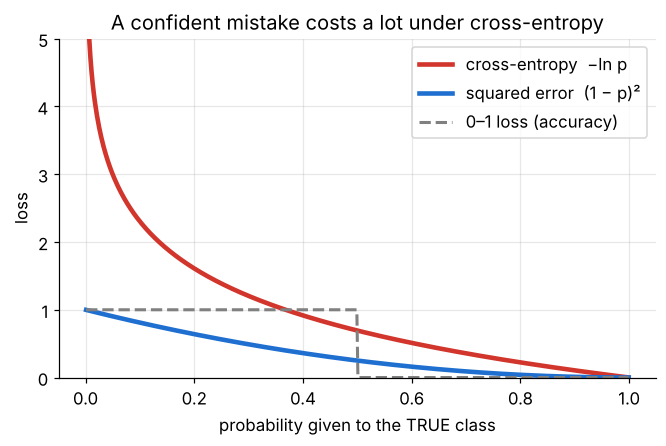

 p(true) | cross-entropy | squared error
   0.99  |     0.010     |    0.0001
   0.90  |     0.105     |    0.0100
   0.50  |     0.693     |    0.2500
   0.10  |     2.303     |    0.8100
   0.01  |     4.605     |    0.9801


In [20]:
p = np.linspace(0.001, 0.999, 500)
plt.plot(p, -np.log(p), lw=3, color=RED, label="cross-entropy  −ln p")
plt.plot(p, (1 - p) ** 2, lw=3, color=BLUE, label="squared error  (1 − p)²")
plt.plot(p, (p < 0.5).astype(float), lw=2, ls="--", color="gray", label="0–1 loss (accuracy)")
plt.ylim(0, 5); plt.xlabel("probability given to the TRUE class"); plt.ylabel("loss"); plt.legend()
plt.title("A confident mistake costs a lot under cross-entropy"); plt.show()

print(" p(true) | cross-entropy | squared error")
for pt in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(f"  {pt:5.2f}  |    {-np.log(pt):6.3f}     |    {(1-pt)**2:6.4f}")

**Why not MSE for a sigmoid classifier?** The gradient of each loss with respect to the score $z$:

* cross-entropy: $p - y$
* MSE: $2(p-y)\,p\,(1-p)$, which vanishes when $p$ is near 0 or 1, even if the answer is badly wrong.

In [21]:
y_true, p_wrong = 1.0, 0.01                         # the model is confidently WRONG
grad_ce  = p_wrong - y_true
grad_mse = 2 * (p_wrong - y_true) * p_wrong * (1 - p_wrong)
print(f"cross-entropy gradient: {grad_ce:.4f}")
print(f"MSE gradient:           {grad_mse:.4f}   ({grad_ce / grad_mse:.0f}× weaker)")

cross-entropy gradient: -0.9900
MSE gradient:           -0.0196   (51× weaker)


## 4.4 Many classes: softmax and categorical cross-entropy

$$p_j = \frac{e^{z_j}}{\sum_m e^{z_m}}, \qquad L = -\ln p_{\text{true}}$$

In code we subtract the largest score first. It does not change the answer, but it stops $e^{z}$ from overflowing.

In [22]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    ez = np.exp(z - z.max())                 # numerically stable
    return ez / ez.sum()

def categorical_ce(z, true_index):
    return -np.log(softmax(z)[true_index])

logits = [2.0, 1.0, 0.1]                     # cat, dog, bird
probs = softmax(logits)
print("probabilities:", probs.round(3), " sum =", probs.sum())
for i, name in enumerate(["cat", "dog", "bird"]):
    print(f"loss if the true class is {name:4s}: {categorical_ce(logits, i):.3f}")

probabilities: [0.659 0.242 0.099]  sum = 1.0
loss if the true class is cat : 0.417
loss if the true class is dog : 1.417
loss if the true class is bird: 2.317


## 4.5 Hinge loss (support vector machines)

With labels $y\in\{-1,+1\}$ and margin $m = y\,z$: hinge $=\max(0, 1-m)$. For comparison we draw the logistic loss $\log_2(1+e^{-m})$, which is cross-entropy written in terms of the margin.

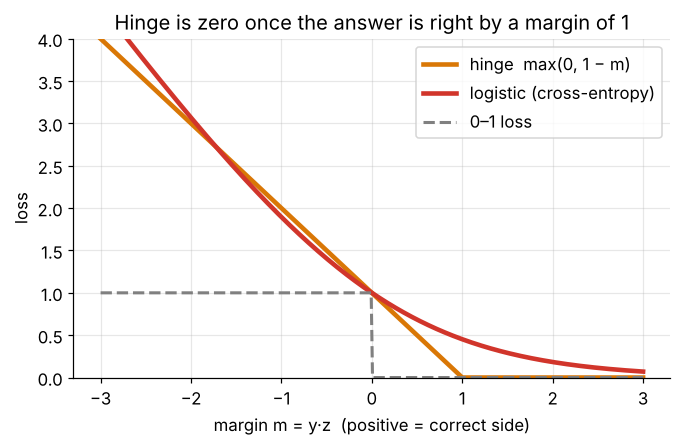

In [23]:
m = np.linspace(-3, 3, 400)
plt.plot(m, np.maximum(0, 1 - m), lw=3, color="#d97706", label="hinge  max(0, 1 − m)")
plt.plot(m, np.log2(1 + np.exp(-m)), lw=3, color=RED, label="logistic (cross-entropy)")
plt.plot(m, (m < 0).astype(float), lw=2, ls="--", color="gray", label="0–1 loss")
plt.xlabel("margin m = y·z  (positive = correct side)"); plt.ylabel("loss"); plt.ylim(0, 4); plt.legend()
plt.title("Hinge is zero once the answer is right by a margin of 1"); plt.show()

### Exercises — Part 4
1. Compute MSE, MAE and Huber ($\delta = 1$) by hand for the errors $0.5, 2, -3$. Check with code.
2. Compute `softmax([1, 2, 3])` and the loss when the true class is the first one.
3. Try the naive softmax `np.exp(z) / np.exp(z).sum()` with `z = [1000, 1001]`. What goes wrong? Why does the stable version work?
4. In Section 4.2, move one outlier much further away (e.g. $y=-5$). How much does each slope change?

---
# Part 5. Overfitting and underfitting

**Big idea.** We train on one set of data but care about **new** data. So we keep a **test set** aside.

* **Underfitting**: model too simple. Training error and test error both high.
* **Overfitting**: model too flexible. Training error tiny, test error large. The **gap** is the warning sign.

$$\text{expected test error} = \text{Bias}^2 + \text{Variance} + \sigma^2$$

## 5.1 Data with a hidden true pattern

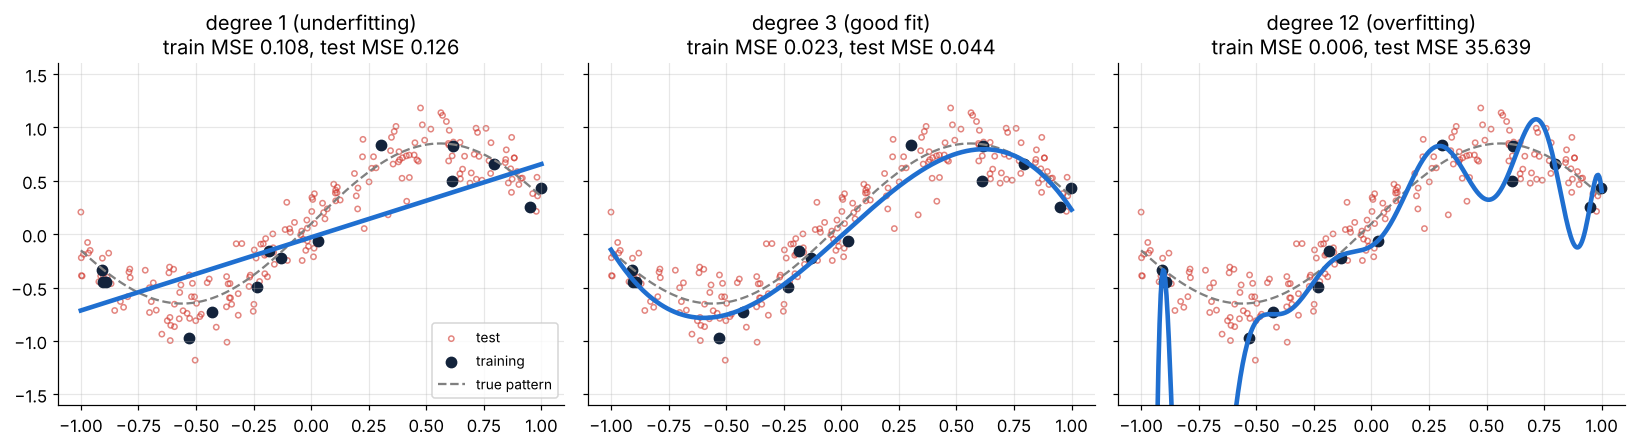

In [24]:
true_f = lambda x: 0.75 * np.sin(2.8 * x) + 0.1
NOISE = 0.2

def make_data(n, rng, noise=NOISE):
    x = rng.uniform(-1, 1, n)
    return x, true_f(x) + rng.normal(0, noise, n)

rng = np.random.default_rng(5)
x_tr, y_tr = make_data(15, rng)      # small training set
x_te, y_te = make_data(200, rng)     # test set: never used for fitting

def errors(degree, lam=0.0, x_train=None, y_train=None):
    x_train = x_tr if x_train is None else x_train
    y_train = y_tr if y_train is None else y_train
    w = fit_poly(x_train, y_train, degree, lam)
    return mse(predict_poly(w, x_train), y_train), mse(predict_poly(w, x_te), y_te), w

xx = np.linspace(-1, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, d, label in zip(axes, [1, 3, 12], ["underfitting", "good fit", "overfitting"]):
    tr, te, w = errors(d)
    ax.scatter(x_te, y_te, s=12, facecolor="none", edgecolor=RED, alpha=0.6, label="test")
    ax.scatter(x_tr, y_tr, s=45, color="#13233b", label="training")
    ax.plot(xx, true_f(xx), "--", color="gray", label="true pattern")
    ax.plot(xx, predict_poly(w, xx), lw=3, color=BLUE)
    ax.set_ylim(-1.6, 1.6)
    ax.set_title(f"degree {d} ({label})\ntrain MSE {tr:.3f}, test MSE {te:.3f}")
axes[0].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## 5.2 The complexity curve

Training error always falls as the degree grows. Test error falls, then rises: a **U shape**. The best model sits at the bottom of the test curve.

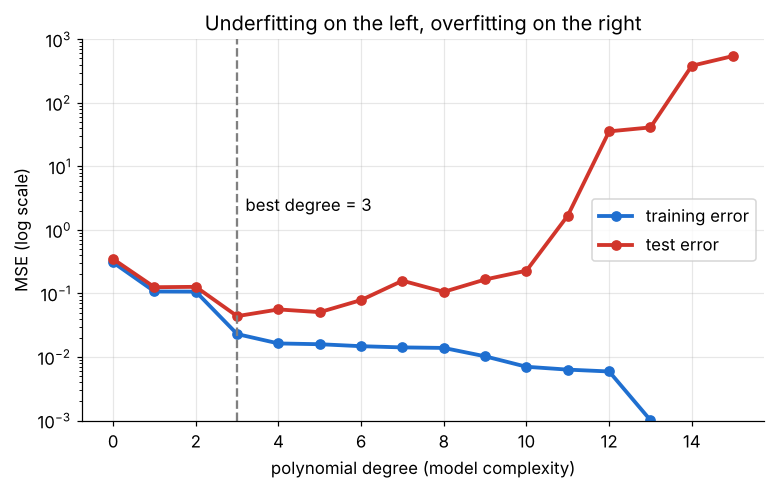

In [25]:
degrees = np.arange(0, 16)
tr_err, te_err = zip(*[errors(d)[:2] for d in degrees])
best = degrees[np.argmin(te_err)]

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, tr_err, "o-", lw=2.5, color=BLUE, label="training error")
plt.plot(degrees, te_err, "o-", lw=2.5, color=RED, label="test error")
plt.axvline(best, ls="--", color="gray"); plt.text(best + 0.2, 2, f"best degree = {best}")
plt.yscale("log"); plt.ylim(1e-3, 1e3); plt.xlabel("polynomial degree (model complexity)"); plt.ylabel("MSE (log scale)")
plt.title("Underfitting on the left, overfitting on the right"); plt.legend(); plt.show()

One random sample is noisy. Repeating the experiment on **200 different training sets** and taking the median shows the typical behaviour. (These are the numbers charted in the handbook.)

In [26]:
rng = np.random.default_rng(11)
all_tr, all_te = [], []
for _ in range(200):
    xs_, ys_ = make_data(15, rng)
    row_tr, row_te = [], []
    for d in degrees:
        w_ = fit_poly(xs_, ys_, d)
        row_tr.append(mse(predict_poly(w_, xs_), ys_)); row_te.append(mse(predict_poly(w_, x_te), y_te))
    all_tr.append(row_tr); all_te.append(row_te)
median_tr, median_te = np.median(all_tr, axis=0), np.median(all_te, axis=0)
print("degree | median train MSE | median test MSE")
for d in degrees:
    print(f"{d:6d} | {median_tr[d]:16.4f} | {median_te[d]:15.4f}")

degree | median train MSE | median test MSE
     0 |           0.3271 |          0.3502
     1 |           0.0910 |          0.1172
     2 |           0.0760 |          0.1277
     3 |           0.0268 |          0.0486
     4 |           0.0246 |          0.0569
     5 |           0.0208 |          0.0757
     6 |           0.0181 |          0.1422
     7 |           0.0160 |          0.3059
     8 |           0.0128 |          0.9703
     9 |           0.0103 |          6.3737
    10 |           0.0089 |         57.2304
    11 |           0.0063 |       1493.6032
    12 |           0.0040 |      83489.7276
    13 |           0.0012 |    7523296.3269
    14 |           0.0000 | 3008964165.5224
    15 |           0.0000 | 1389620303.7796


## 5.3 Bias and variance, measured

Fit the same degree on many different training sets and look at the predictions:

* **Bias²**: how far the *average* prediction is from the true pattern.
* **Variance**: how much the predictions *spread* between training sets.

degree |  bias²  | variance
     1 |  0.0526 |   0.0149
     3 |  0.0011 |   0.0770
     5 |  0.0021 |   0.3363


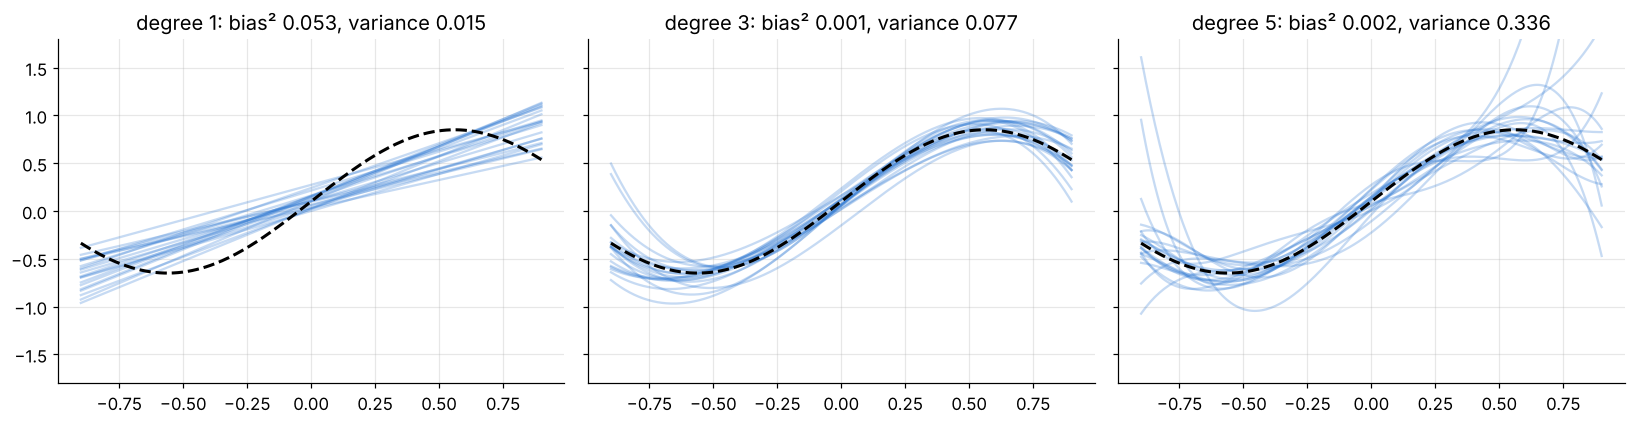

In [27]:
rng = np.random.default_rng(12)
grid = np.linspace(-0.9, 0.9, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
print("degree |  bias²  | variance")
for ax, d in zip(axes, [1, 3, 5]):
    preds = []
    for _ in range(100):
        xs_, ys_ = make_data(15, rng)
        preds.append(predict_poly(fit_poly(xs_, ys_, d), grid))
    preds = np.array(preds)
    bias2 = np.mean((preds.mean(axis=0) - true_f(grid)) ** 2)
    var = np.mean(preds.var(axis=0))
    print(f"{d:6d} | {bias2:7.4f} | {var:8.4f}")
    for pr in preds[:20]:
        ax.plot(grid, pr, color=BLUE, alpha=0.25)
    ax.plot(grid, true_f(grid), "--", color="black", lw=2)
    ax.set_ylim(-1.8, 1.8); ax.set_title(f"degree {d}: bias² {bias2:.3f}, variance {var:.3f}")
plt.tight_layout(); plt.show()

Degree 1 fits all agree with each other but are all wrong (high bias). Degree 5 fits follow the pattern on average but disagree with each other much more (high variance). At higher degrees the variance explodes.

## 5.4 Regularization tames overfitting

Ridge regression adds $\lambda\sum w_j^2$ to the loss. We keep the over-flexible degree 12 and only change $\lambda$.

    λ    | train MSE | test MSE
   0e+00 |    0.0059 |  35.6387
   1e-05 |    0.0138 |   0.1047
   1e-04 |    0.0150 |   0.0887
   1e-03 |    0.0159 |   0.0889
   1e-02 |    0.0284 |   0.0665
   1e-01 |    0.0934 |   0.1224
   1e+00 |    0.1964 |   0.2477


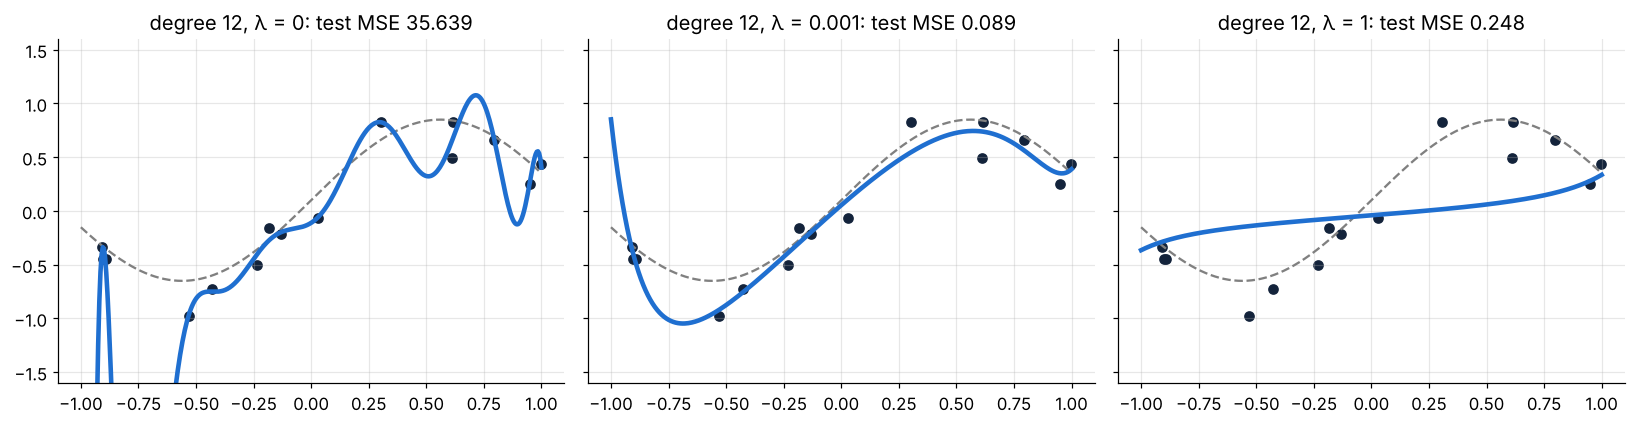

In [28]:
lams = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
print("    λ    | train MSE | test MSE")
for lam in lams:
    tr, te, _ = errors(12, lam)
    print(f"{lam:8.0e} | {tr:9.4f} | {te:8.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, lam in zip(axes, [0, 1e-3, 1]):
    tr, te, w = errors(12, lam)
    ax.scatter(x_tr, y_tr, color="#13233b"); ax.plot(xx, true_f(xx), "--", color="gray")
    ax.plot(xx, predict_poly(w, xx), lw=3, color=BLUE); ax.set_ylim(-1.6, 1.6)
    ax.set_title(f"degree 12, λ = {lam:g}: test MSE {te:.3f}")
plt.tight_layout(); plt.show()

Too little $\lambda$: overfitting. Too much: every weight is squeezed to zero and the model underfits.

## 5.5 Learning curves: does more data help?

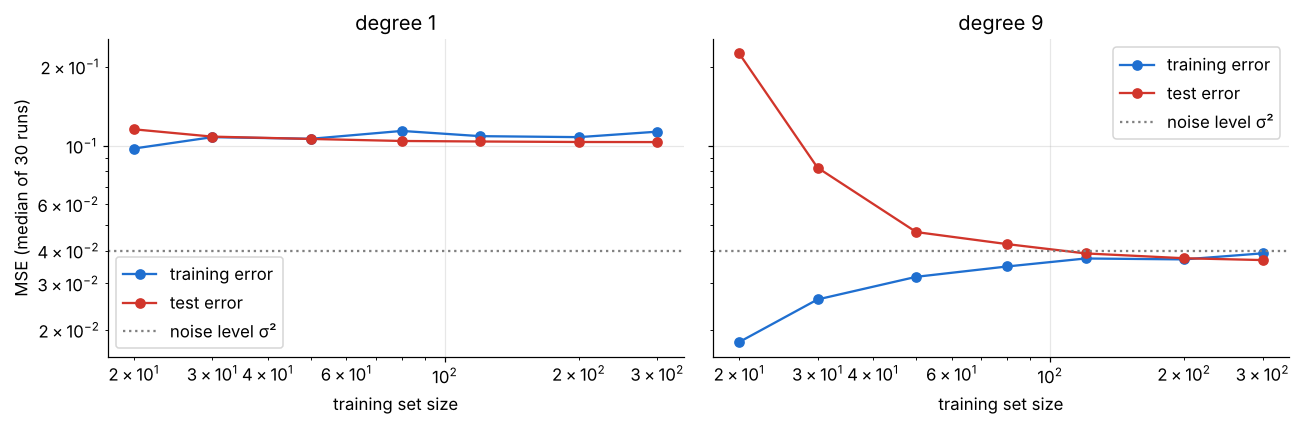

In [29]:
rng = np.random.default_rng(13)
sizes = [20, 30, 50, 80, 120, 200, 300]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, d in zip(axes, [1, 9]):
    tr_m, te_m = [], []
    for n_ in sizes:
        t1, t2 = [], []
        for _ in range(30):
            xs_, ys_ = make_data(n_, rng)
            w_ = fit_poly(xs_, ys_, d)
            t1.append(mse(predict_poly(w_, xs_), ys_)); t2.append(mse(predict_poly(w_, x_te), y_te))
        tr_m.append(np.median(t1)); te_m.append(np.median(t2))
    ax.plot(sizes, tr_m, "o-", color=BLUE, label="training error")
    ax.plot(sizes, te_m, "o-", color=RED, label="test error")
    ax.axhline(NOISE ** 2, ls=":", color="gray", label="noise level σ²")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training set size")
    ax.set_title(f"degree {d}"); ax.legend()
axes[0].set_ylabel("MSE (median of 30 runs)")
plt.tight_layout(); plt.show()

* **Degree 1 (underfitting):** both curves flatten high and close together. More data does **not** help; a better model does.
* **Degree 9 (overfitting):** a large gap that shrinks as data grows. More data **does** help.

## 5.6 Choosing the degree with k-fold cross-validation

We must not use the test set to choose the degree. Instead, split the training data into $k$ folds, train on $k-1$, validate on the remaining one, rotate, and average.

degree chosen by 5-fold CV: 3
degree that is best on the test set: 5


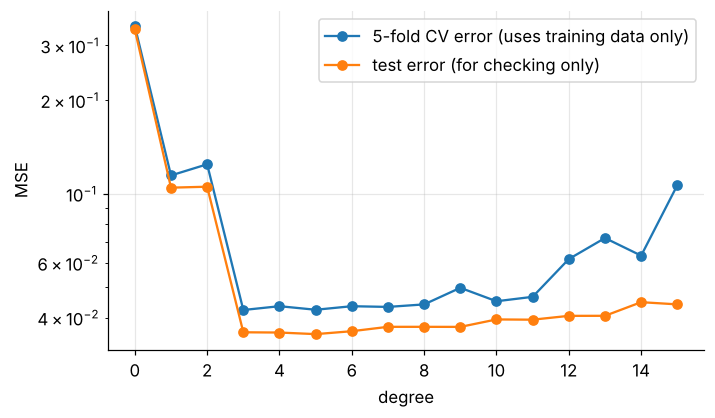

In [30]:
def kfold_cv_mse(x, y, degree, k=5, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x))
    folds = np.array_split(idx, k)
    scores = []
    for i in range(k):
        val = folds[i]
        trn = np.concatenate([folds[j] for j in range(k) if j != i])
        w_ = fit_poly(x[trn], y[trn], degree)
        scores.append(mse(predict_poly(w_, x[val]), y[val]))
    return np.mean(scores)

rng = np.random.default_rng(21)
x_cv, y_cv = make_data(60, rng)
cv = [kfold_cv_mse(x_cv, y_cv, d) for d in degrees]
test_scores = [mse(predict_poly(fit_poly(x_cv, y_cv, d), x_te), y_te) for d in degrees]
print("degree chosen by 5-fold CV:", degrees[np.argmin(cv)])
print("degree that is best on the test set:", degrees[np.argmin(test_scores)])

plt.plot(degrees, cv, "o-", label="5-fold CV error (uses training data only)")
plt.plot(degrees, test_scores, "o-", label="test error (for checking only)")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("MSE"); plt.legend(); plt.show()

### Exercises — Part 5
1. Change the training set size in Section 5.1 from 15 to 100. Re-run 5.1 and 5.2. What happens to the best degree and to the overfitting?
2. Set `NOISE = 0` (and re-run from 5.1). Does overfitting still happen? Why?
3. Using `kfold_cv_mse`, choose **both** the degree (0–12) and $\lambda$ (from `lams`) for `x_cv, y_cv`.
4. Explain in one sentence each: bias, variance, irreducible noise.

---
# Part 6. Optimizers

**Big idea.** Every optimizer follows the gradient; they differ in what they **remember**.

| Optimizer | Update |
|---|---|
| Gradient descent | $\theta \leftarrow \theta - \eta g$ |
| Momentum | $v \leftarrow \beta v - \eta g,\ \ \theta \leftarrow \theta + v$ |
| Nesterov | $v \leftarrow \beta v - \eta\nabla L(\theta+\beta v),\ \ \theta \leftarrow \theta + v$ |
| AdaGrad | $G \leftarrow G + g^2,\ \ \theta \leftarrow \theta - \eta g/(\sqrt G+\epsilon)$ |
| RMSProp | $s \leftarrow \rho s + (1-\rho)g^2,\ \ \theta \leftarrow \theta - \eta g/(\sqrt s+\epsilon)$ |
| Adam | $m \leftarrow \beta_1 m+(1-\beta_1)g,\ v \leftarrow \beta_2 v+(1-\beta_2)g^2,\ \theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ |

## 6.1 The six optimizers as code

Each optimizer gets the current parameters and a function that returns the gradient, and returns the new parameters.

In [31]:
class GD:
    def __init__(self, lr): self.lr = lr
    def step(self, theta, grad_fn):
        return theta - self.lr * grad_fn(theta)

class Momentum:
    def __init__(self, lr, beta=0.9): self.lr, self.beta, self.v = lr, beta, None
    def step(self, theta, grad_fn):
        if self.v is None: self.v = np.zeros_like(theta)
        self.v = self.beta * self.v - self.lr * grad_fn(theta)
        return theta + self.v

class Nesterov(Momentum):
    def step(self, theta, grad_fn):
        if self.v is None: self.v = np.zeros_like(theta)
        self.v = self.beta * self.v - self.lr * grad_fn(theta + self.beta * self.v)   # look ahead
        return theta + self.v

class AdaGrad:
    def __init__(self, lr, eps=1e-8): self.lr, self.eps, self.G = lr, eps, None
    def step(self, theta, grad_fn):
        g = grad_fn(theta)
        self.G = g**2 if self.G is None else self.G + g**2
        return theta - self.lr * g / (np.sqrt(self.G) + self.eps)

class RMSProp:
    def __init__(self, lr, rho=0.9, eps=1e-8): self.lr, self.rho, self.eps, self.s = lr, rho, eps, None
    def step(self, theta, grad_fn):
        g = grad_fn(theta)
        self.s = (1 - self.rho) * g**2 if self.s is None else self.rho * self.s + (1 - self.rho) * g**2
        return theta - self.lr * g / (np.sqrt(self.s) + self.eps)

class Adam:
    def __init__(self, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.m, self.v, self.t = lr, b1, b2, eps, None, None, 0
    def step(self, theta, grad_fn):
        g = grad_fn(theta)
        if self.m is None: self.m, self.v = np.zeros_like(theta), np.zeros_like(theta)
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g**2
        m_hat = self.m / (1 - self.b1**self.t)          # bias correction
        v_hat = self.v / (1 - self.b2**self.t)
        return theta - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

def run(opt, theta0, grad_fn, loss_fn, steps):
    theta = np.array(theta0, dtype=float)
    path, losses = [theta.copy()], [loss_fn(theta)]
    for _ in range(steps):
        theta = opt.step(theta, grad_fn)
        if not np.all(np.isfinite(theta)) or np.abs(theta).max() > 1e6:
            break
        path.append(theta.copy()); losses.append(loss_fn(theta))
    return np.array(path), np.array(losses)

## 6.2 Race on two classic surfaces

* **Narrow valley** $f = 0.03x^2 + 2y^2$: steep across, gentle along.
* **Rosenbrock (banana valley)** $f = (1-x)^2 + 100(y-x^2)^2$: minimum at $(1,1)$ at the end of a long curved valley.

Each optimizer gets its own learning rate (the same defaults as the Learning Lab).

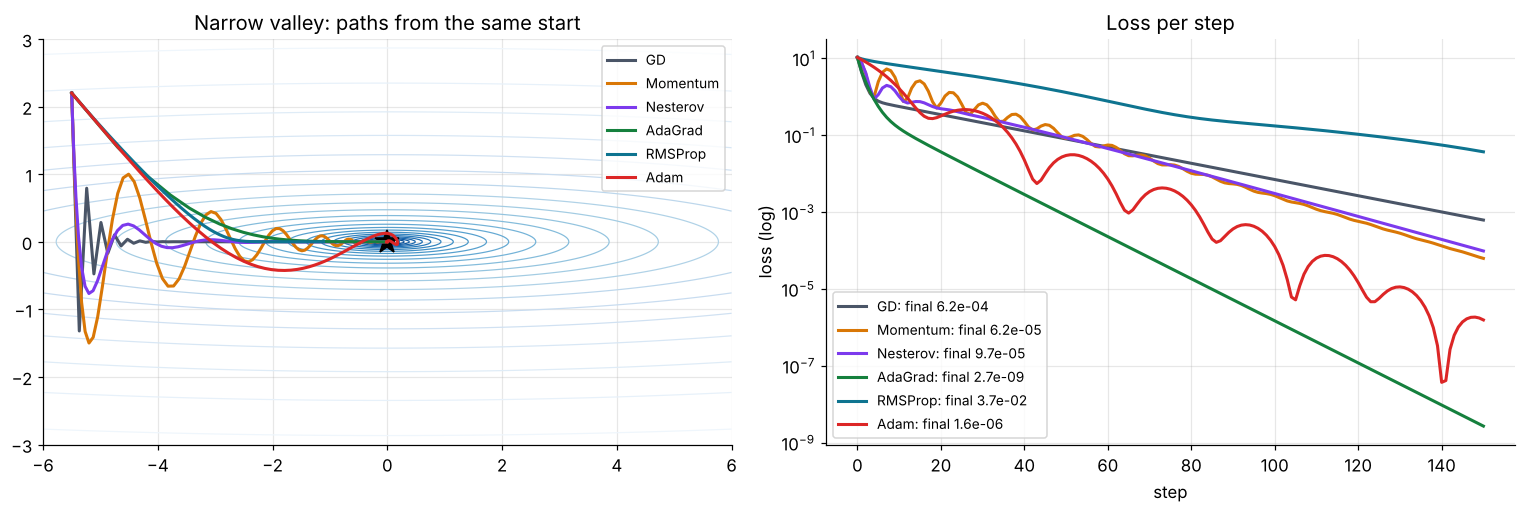

In [32]:
SURFACES = {
    "Narrow valley": dict(
        f=lambda t: 0.03 * t[0]**2 + 2 * t[1]**2,
        g=lambda t: np.array([0.06 * t[0], 4 * t[1]]),
        start=[-5.5, 2.2], box=(-6, 6, -3, 3), minimum=(0, 0), steps=150,
        lr=dict(GD=0.4, Momentum=0.04, Nesterov=0.04, AdaGrad=0.8, RMSProp=0.03, Adam=0.15)),
    "Rosenbrock": dict(
        f=lambda t: (1 - t[0])**2 + 100 * (t[1] - t[0]**2)**2,
        g=lambda t: np.array([-2 * (1 - t[0]) - 400 * t[0] * (t[1] - t[0]**2), 200 * (t[1] - t[0]**2)]),
        start=[-1.2, 1.6], box=(-2, 2, -1, 3), minimum=(1, 1), steps=1500,
        lr=dict(GD=0.0015, Momentum=0.0003, Nesterov=0.0003, AdaGrad=0.5, RMSProp=0.01, Adam=0.05)),
}
MAKERS = dict(GD=GD, Momentum=Momentum, Nesterov=Nesterov, AdaGrad=AdaGrad, RMSProp=RMSProp, Adam=Adam)

def race(name, which=None):
    S = SURFACES[name]
    which = which or list(MAKERS)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    x0, x1, y0, y1 = S["box"]
    gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    Z = S["f"](np.array([gx, gy]))
    axes[0].contour(gx, gy, np.log(Z + 1e-3), levels=25, cmap="Blues_r", linewidths=0.8)
    axes[0].plot(*S["minimum"], "k*", ms=16)
    for opt_name in which:
        path, losses = run(MAKERS[opt_name](S["lr"][opt_name]), S["start"], S["g"], S["f"], S["steps"])
        axes[0].plot(path[:, 0], path[:, 1], "-", lw=2, color=COLORS[opt_name], label=opt_name)
        axes[1].plot(losses + 1e-12, lw=2, color=COLORS[opt_name], label=f"{opt_name}: final {losses[-1]:.1e}")
    axes[0].set_xlim(x0, x1); axes[0].set_ylim(y0, y1); axes[0].set_title(f"{name}: paths from the same start")
    axes[0].legend(fontsize=9)
    axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("loss (log)")
    axes[1].set_title("Loss per step"); axes[1].legend(fontsize=9)
    plt.tight_layout(); plt.show()

race("Narrow valley")

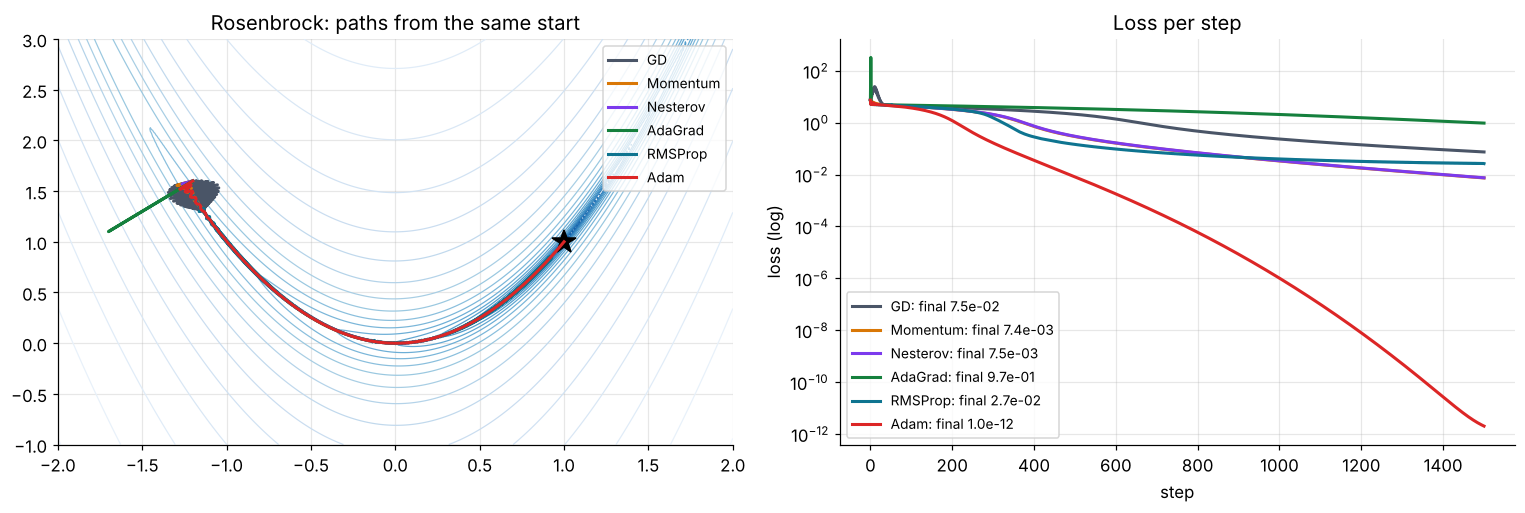

In [33]:
race("Rosenbrock")

## 6.3 Momentum can roll out of a local minimum

$f(x, y) = 0.25x^4 - x^2 + 0.3x + 0.5y^2$ has a shallow valley on the right and a deeper one on the left.

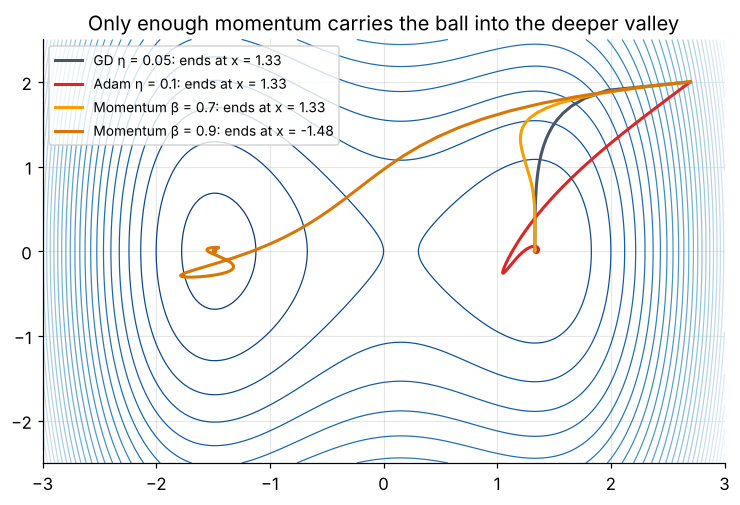

In [34]:
f_lg = lambda t: 0.25 * t[0]**4 - t[0]**2 + 0.3 * t[0] + 0.5 * t[1]**2
g_lg = lambda t: np.array([t[0]**3 - 2 * t[0] + 0.3, t[1]])
gx, gy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2.5, 2.5, 300))
plt.figure(figsize=(8, 5))
plt.contour(gx, gy, f_lg(np.array([gx, gy])), levels=30, cmap="Blues_r", linewidths=0.8)
for label, opt, c in [("GD η = 0.05", GD(0.05), COLORS["GD"]),
                      ("Adam η = 0.1", Adam(0.1), COLORS["Adam"]),
                      ("Momentum β = 0.7", Momentum(0.01, 0.7), "#f59f00"),
                      ("Momentum β = 0.9", Momentum(0.01, 0.9), COLORS["Momentum"])]:
    path, losses = run(opt, [2.7, 2.0], g_lg, f_lg, 800)
    plt.plot(path[:, 0], path[:, 1], lw=2, color=c, label=f"{label}: ends at x = {path[-1, 0]:.2f}")
plt.legend(fontsize=9); plt.title("Only enough momentum carries the ball into the deeper valley"); plt.show()

## 6.4 Mini-batch SGD: cheaper, noisier steps

Real datasets are big, so each update uses a small random **mini-batch** instead of all the data. One **epoch** = one pass through the data.

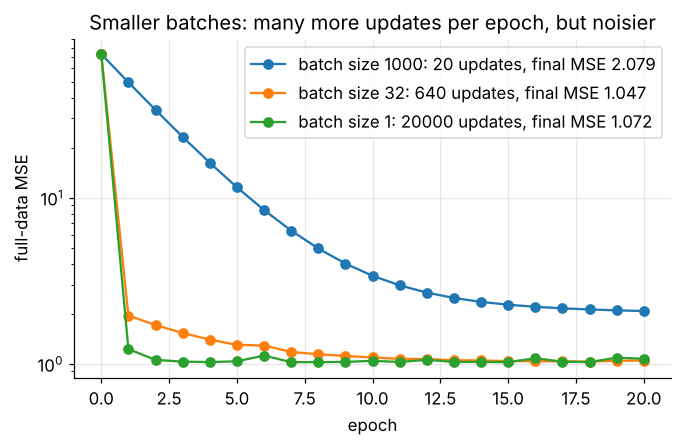

In [35]:
rng = np.random.default_rng(31)
n_big = 1000
xb = rng.uniform(0, 5, n_big); yb = 3 + 2 * xb + rng.normal(0, 1, n_big)
Xb = np.column_stack([np.ones(n_big), xb])
full_loss = lambda th: np.mean((Xb @ th - yb) ** 2)

def minibatch_sgd(batch_size, lr=0.01, epochs=20, seed=0):
    r = np.random.default_rng(seed); th = np.zeros(2); hist = [full_loss(th)]
    for _ in range(epochs):
        order = r.permutation(n_big)
        for start in range(0, n_big, batch_size):
            idx = order[start:start + batch_size]
            grad = 2 * Xb[idx].T @ (Xb[idx] @ th - yb[idx]) / len(idx)
            th = th - lr * grad
        hist.append(full_loss(th))
    return th, hist

for bs in [1000, 32, 1]:
    th, hist = minibatch_sgd(bs, lr=0.01 if bs > 1 else 0.002)
    updates = 20 * int(np.ceil(n_big / bs))
    plt.plot(hist, "o-", label=f"batch size {bs}: {updates} updates, final MSE {hist[-1]:.3f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("full-data MSE"); plt.legend()
plt.title("Smaller batches: many more updates per epoch, but noisier"); plt.show()

## 6.5 Optimizers on a real model

Logistic regression with degree-2 features on the circle data from Part 3. The parameters are $\theta = (w_1,\dots,w_5, b)$.

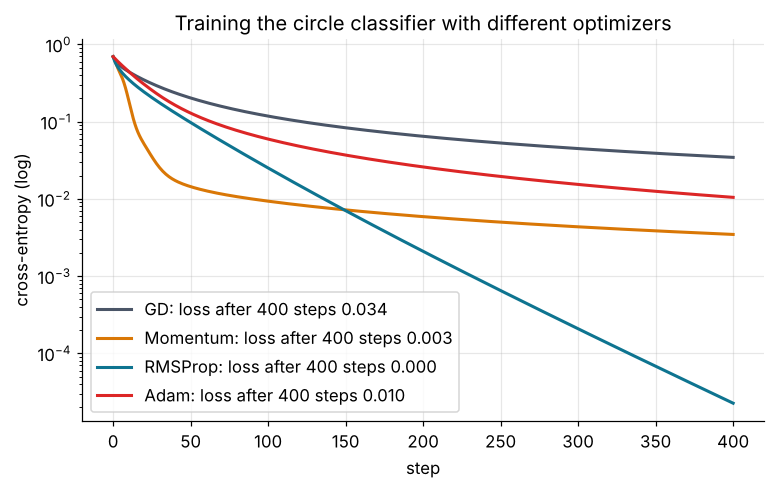

In [36]:
Fc = quadratic(Xc)
Fc1 = np.c_[Fc, np.ones(len(Fc))]                       # last column = bias

def lr_loss(th):  return bce(sigmoid(Fc1 @ th), yc)
def lr_grad(th):  return Fc1.T @ (sigmoid(Fc1 @ th) - yc) / len(yc)

plt.figure(figsize=(8, 4.5))
for name, opt in [("GD", GD(0.3)), ("Momentum", Momentum(0.3, 0.9)),
                  ("RMSProp", RMSProp(0.05)), ("Adam", Adam(0.05))]:
    _, losses = run(opt, np.zeros(Fc1.shape[1]), lr_grad, lr_loss, 400)
    plt.plot(losses, lw=2, color=COLORS[name], label=f"{name}: loss after 400 steps {losses[-1]:.3f}")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("cross-entropy (log)"); plt.legend()
plt.title("Training the circle classifier with different optimizers"); plt.show()

### Exercises — Part 6
1. On the narrow valley, run `Momentum` with $\beta$ = 0, 0.5, 0.9 and 0.99 (same $\eta$ = 0.04). Which is fastest? What happens at 0.99?
2. On Rosenbrock, raise the GD learning rate until it diverges. What is roughly the largest value that still works?
3. Add a **step-decay schedule** to the mini-batch SGD of Section 6.4 (batch size 1): halve the learning rate every 5 epochs. Is the final MSE lower?
4. Why does AdaGrad stop making progress on Rosenbrock? Print `np.sqrt(opt.G)` after the run to see.

---
# Summary

| Lesson | One-sentence takeaway |
|---|---|
| Gradient descent | Step against the slope: $\theta \leftarrow \theta - \eta\nabla L$; the learning rate must be neither too small nor too big. |
| Regression | Predict numbers by minimising MSE; the normal equation gives the exact line. |
| Classification | Sigmoid turns a score into a probability; train with cross-entropy; boundary at $z=0$. |
| Loss functions | MSE for regression, MAE/Huber with outliers, cross-entropy for classification. |
| Overfitting | Judge models on unseen data; fix overfitting with more data, simpler models or regularization. |
| Optimizers | Momentum smooths, adaptive methods rescale each parameter, Adam combines both. |

---
# Appendix: exercise solutions

### Part 1

In [37]:
# 1.1  f(x) = (x − 3)² ends at the minimum x = 3
p = gradient_descent_1d(lambda x: 2 * (x - 3), 0.0, 0.1, 50)
print("1.1 final x:", round(p[-1], 4))

# 1.2  f(x) = 4x²: x_new = (1 − 8η)x converges when |1 − 8η| < 1, so η < 0.25
for lr in [0.24, 0.25, 0.26]:
    p = gradient_descent_1d(lambda x: 8 * x, 1.0, lr, 100)
    print(f"1.2 η = {lr}: |x| after 100 steps = {abs(p[-1]):.3g}")

# 1.3  which learning rates reach the global minimum (x ≈ −1.30) from x0 = 2?
for lr in [0.02, 0.06, 0.12, 0.2]:
    p = gradient_descent_1d(dg, 2.0, lr, 300)
    print(f"1.3 η = {lr}: ends at {p[-1]:.3f}" if np.isfinite(p[-1]) and abs(p[-1]) < 10 else f"1.3 η = {lr}: diverged")

1.1 final x: 3.0
1.2 η = 0.24: |x| after 100 steps = 0.000239
1.2 η = 0.25: |x| after 100 steps = 1
1.2 η = 0.26: |x| after 100 steps = 2.2e+03
1.3 η = 0.02: ends at 1.131
1.3 η = 0.06: ends at 1.131
1.3 η = 0.12: ends at -1.301
1.3 η = 0.2: diverged


### Part 2

In [38]:
# 2.1  recover y = 1 − 3x
rng = np.random.default_rng(100)
xs_ = rng.uniform(0, 5, 80); ys_ = 1 - 3 * xs_ + rng.normal(0, 1, 80)
a, s = 0.0, 0.0
for _ in range(3000):
    ga, gs = mse_gradients(xs_, ys_, a, s); a -= 0.02 * ga; s -= 0.02 * gs
print(f"2.1 learned ŷ = {a:.2f} + ({s:.2f})x")

# 2.2  η = 0.2 is beyond the stable limit for these x values: the loss explodes
w0_, w1_ = 0.0, 0.0
for epoch in range(8):
    g0_, g1_ = mse_gradients(x, y, w0_, w1_); w0_ -= 0.2 * g0_; w1_ -= 0.2 * g1_
    print(f"2.2 epoch {epoch}: MSE = {mse(predict(x, w0_, w1_), y):.3g}")

# 2.3  the lowest TRAINING error is not necessarily the best model
for d in [1, 2, 6]:
    print(f"2.3 degree {d}: training MSE = {mse(predict_poly(fit_poly(xq, yq, d), xq), yq):.3f}")

2.1 learned ŷ = 0.98 + (-2.97)x
2.2 epoch 0: MSE = 670
2.2 epoch 1: MSE = 5.78e+03
2.2 epoch 2: MSE = 4.99e+04
2.2 epoch 3: MSE = 4.31e+05
2.2 epoch 4: MSE = 3.72e+06
2.2 epoch 5: MSE = 3.21e+07
2.2 epoch 6: MSE = 2.77e+08
2.2 epoch 7: MSE = 2.4e+09
2.3 degree 1: training MSE = 1.131
2.3 degree 2: training MSE = 0.157
2.3 degree 6: training MSE = 0.125


### Part 3

In [39]:
# 3.1  XOR needs the feature x1·x2
rng = np.random.default_rng(101)
centers = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1]])
Xx = np.vstack([rng.normal(c, 0.35, (40, 2)) for c in centers])
yx = np.r_[np.zeros(80), np.ones(80)]                 # label 1 when x1·x2 < 0
for name, fn in [("linear", lambda X: X), ("with x1·x2", lambda X: np.c_[X, X[:, 0] * X[:, 1]])]:
    w_, b_, _ = train_logistic(fn(Xx), yx, lr=0.5, epochs=2000)
    print(f"3.1 {name}: accuracy {np.mean((sigmoid(fn(Xx) @ w_ + b_) >= 0.5) == yx):.0%}")

# 3.2  imbalanced data: always predicting 0
yi = np.r_[np.zeros(190), np.ones(10)]
print("3.2", classification_report(yi, np.zeros_like(yi)))

# 3.3  start from a confidently WRONG model and compare the two gradients
def train_from(F, y, w_init, kind, lr=0.5, epochs=300):
    w_, b_, losses = np.array(w_init, float), 0.0, []
    for _ in range(epochs):
        p_ = sigmoid(F @ w_ + b_)
        e_ = (p_ - y) if kind == "cross-entropy" else 2 * (p_ - y) * p_ * (1 - p_)
        w_ -= lr * F.T @ e_ / len(y); b_ -= lr * e_.mean(); losses.append(bce(p_, y))
    return np.array(losses)
for kind in ["cross-entropy", "MSE"]:
    L_ = train_from(X2, y2, [-4.0, -4.0], kind)
    print(f"3.3 {kind:13s} gradient: loss at epochs 0, 50, 300 = {L_[0]:.2f}, {L_[49]:.2f}, {L_[-1]:.3f}")

3.1 linear: accuracy 52%
3.1 with x1·x2: accuracy 100%
3.2 {'TP': np.int64(0), 'FP': np.int64(0), 'FN': np.int64(10), 'TN': np.int64(190), 'accuracy': np.float64(0.95), 'precision': 0.0, 'recall': np.float64(0.0), 'F1': 0.0}
3.3 cross-entropy gradient: loss at epochs 0, 50, 300 = 8.15, 0.05, 0.013
3.3 MSE           gradient: loss at epochs 0, 50, 300 = 8.15, 7.89, 5.401


### Part 4

In [40]:
# 4.1
e_ = np.array([0.5, 2.0, -3.0])
print(f"4.1 MSE = {np.mean(e_**2):.3f}, MAE = {np.mean(np.abs(e_)):.3f}, Huber = {np.mean(huber_loss(e_, 1.0)):.3f}")

# 4.2
print("4.2 softmax([1,2,3]) =", softmax([1, 2, 3]).round(3), " loss (true = first) =", round(categorical_ce([1, 2, 3], 0), 3))

# 4.3  the naive version overflows: e^1000 = inf, and inf / inf = nan
with np.errstate(over="ignore", invalid="ignore"):
    z_ = np.array([1000.0, 1001.0])
    print("4.3 naive:", np.exp(z_) / np.exp(z_).sum(), " stable:", softmax(z_).round(3))

# 4.4  move one outlier far away
yo_far = yo_all.copy(); yo_far[-1] = -5
for name, gfn in grads.items():
    print(f"4.4 {name}: slope {fit_line(xo_all, yo_all, gfn)[1]:.2f} → {fit_line(xo_all, yo_far, gfn)[1]:.2f}")

4.1 MSE = 4.417, MAE = 1.833, Huber = 1.375
4.2 softmax([1,2,3]) = [0.09  0.245 0.665]  loss (true = first) = 2.408
4.3 naive: [nan nan]  stable: [0.269 0.731]


4.4 MSE: slope 0.13 → -0.26


4.4 MAE: slope 0.47 → 0.47


4.4 Huber (δ = 0.15): slope 0.43 → 0.43


### Part 5

In [41]:
# 5.1  more training data: the best degree rises and the overfitting shrinks
rng = np.random.default_rng(102)
x_big, y_big = make_data(100, rng)
te_big = [errors(d, x_train=x_big, y_train=y_big)[1] for d in degrees]
print("5.1 with 100 points, best degree =", degrees[np.argmin(te_big)], "; test MSE at degree 12 =", round(te_big[12], 4))

# 5.2  with no noise there is nothing to memorise (degree 12 test error stays tiny)
rng = np.random.default_rng(103)
x0n, y0n = make_data(15, rng, noise=0.0)
w0n = fit_poly(x0n, y0n, 12)
print("5.2 noise 0, degree 12: test MSE vs the true pattern =", round(mse(predict_poly(w0n, xx), true_f(xx)), 5))

# 5.3  choose degree AND λ by cross-validation
def kfold_cv_mse_lam(x, y, degree, lam, k=5, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x)); folds = np.array_split(idx, k); sc = []
    for i in range(k):
        val = folds[i]; trn = np.concatenate([folds[j] for j in range(k) if j != i])
        sc.append(mse(predict_poly(fit_poly(x[trn], y[trn], degree, lam), x[val]), y[val]))
    return np.mean(sc)
best_combo = min(((kfold_cv_mse_lam(x_cv, y_cv, d, l), d, l) for d in range(13) for l in lams))
print(f"5.3 best by CV: degree {best_combo[1]}, λ = {best_combo[2]:g} (CV MSE {best_combo[0]:.4f})")

5.1 with 100 points, best degree = 3 ; test MSE at degree 12 = 0.0592
5.2 noise 0, degree 12: test MSE vs the true pattern = 0.0
5.3 best by CV: degree 5, λ = 0.0001 (CV MSE 0.0422)


5.4 **Bias**: error from the model's wrong assumptions (it is too simple for the pattern). **Variance**: how much the fitted model changes from one training sample to another. **Irreducible noise**: randomness in the data itself, which no model can remove.

### Part 6

In [42]:
S = SURFACES["Narrow valley"]
# 6.1  momentum values on the narrow valley
for beta in [0, 0.5, 0.9, 0.99]:
    _, losses = run(Momentum(0.04, beta), S["start"], S["g"], S["f"], 150)
    print(f"6.1 β = {beta}: loss after 150 steps = {losses[-1]:.2e}")

# 6.2  largest stable GD learning rate on Rosenbrock (from this start)
R = SURFACES["Rosenbrock"]
for lr in [0.001, 0.002, 0.003, 0.004]:
    path, losses = run(GD(lr), R["start"], R["g"], R["f"], 3000)
    print(f"6.2 η = {lr}: " + ("diverged" if len(path) < 3001 else f"final loss {losses[-1]:.3e}"))

# 6.3  step decay for batch size 1
def minibatch_sgd_decay(batch_size, lr=0.002, epochs=20, seed=0):
    r = np.random.default_rng(seed); th = np.zeros(2)
    for ep in range(epochs):
        cur = lr * 0.5 ** (ep // 5)                     # halve every 5 epochs
        for start in range(0, n_big, batch_size):
            idx = r.permutation(n_big)[:batch_size]
            th = th - cur * 2 * Xb[idx].T @ (Xb[idx] @ th - yb[idx]) / len(idx)
    return full_loss(th)
print(f"6.3 batch 1: constant η → {minibatch_sgd(1, lr=0.002)[1][-1]:.4f}, step decay → {minibatch_sgd_decay(1):.4f}")

# 6.4  AdaGrad's accumulated squares only grow, so its steps shrink toward zero
opt = AdaGrad(0.5); run(opt, R["start"], R["g"], R["f"], 1500)
print("6.4 AdaGrad effective step sizes η/√G at the end:", (0.5 / np.sqrt(opt.G)).round(5))

6.1 β = 0: loss after 150 steps = 4.41e-01
6.1 β = 0.5: loss after 150 steps = 2.15e-01
6.1 β = 0.9: loss after 150 steps = 6.24e-05
6.1 β = 0.99: loss after 150 steps = 6.04e-01


6.2 η = 0.001: final loss 3.515e-02
6.2 η = 0.002: final loss 1.545e-03
6.2 η = 0.003: diverged
6.2 η = 0.004: diverged


6.3 batch 1: constant η → 1.0722, step decay → 1.0240
6.4 AdaGrad effective step sizes η/√G at the end: [0.0004 0.0014]
